# 10 · Integración: pronóstico + fotos → red bayesiana → MDP

Notebook de **análisis**: no entrena nada. Muestra cómo se combinan la evidencia climática y las hojas fotografiadas, qué decide el
QMDP, cuánto aportan al ingreso simulado y qué tan sensible es todo a los supuestos de diseño. Las cifras salen de `experiments/fusion/`
(regenerables con `python -m src.fusion.simulate`, `sensitivity` y `diagnose_climate`).

**Importante:** la relación entre el clima y el nivel de roya de la parcela, la mezcla de hojas y la dinámica del mundo simulado son
**supuestos de diseño** (`configs/fusion.yaml`): no existen datos de incidencia de roya emparejados con clima para medirlos. Lo que se
reporta es el valor de la información *dentro de ese mundo*, no una medición de campo.

In [1]:
import json, sys
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
from src.fusion.config import load_config
from src.fusion.contracts import ClimateEvidence, ClimateWindow
from src.fusion.network_ext import (ExtendedModel, climate_risk_cpt, legacy_r_cpt, load_confusion_counts, obs_given_leaf,
                                    sensitivity_specificity)
from src.fusion.qmdp import qmdp, solve_parcel
from src.mdp.environment import ACTION_NAMES, MONTH_NAMES, ParcelaProfile, state_index
FUS = ROOT / "experiments" / "fusion"
cfg = load_config()
model = ExtendedModel.build(cfg)
print(json.dumps({k: cfg[k] for k in ["rust_bands", "leaf_mix", "climate_risk", "confusion", "leaf_weight", "min_leaves"]}, indent=1, ensure_ascii=False))

{
 "rust_bands": {
  "cuts": [
   0.05,
   0.1
  ],
  "representative_incidence": [
   0.02,
   0.07,
   0.15
  ]
 },
 "leaf_mix": {
  "severe_share": 0.3,
  "other_share": 0.2
 },
 "climate_risk": {
  "neutral_at_least_medium": 0.45,
  "neutral_high": 0.15,
  "slope": 0.5
 },
 "confusion": {
  "source": "pooled",
  "alpha": 1.0
 },
 "leaf_weight": 1.0,
 "min_leaves": 10
}


## 1. La red heredada no sirve para el clima de Guatemala
`P(R | T, H, P)` se estimó con 100 filas del conjunto de la India. Se cuenta en cuántas de las 27 combinaciones de padres tiene datos (el resto queda
en el valor uniforme del suavizado de Laplace).

Combinaciones T×H×P con una distribución distinta de la uniforme: 4 de 27


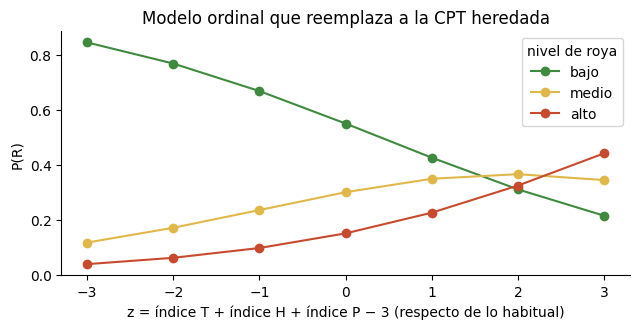

In [2]:
legacy = legacy_r_cpt(ROOT / "data")                      # (R, T, H, P)
uniform = np.isclose(legacy, 1 / 3).all(axis=0)
print(f"Combinaciones T×H×P con una distribución distinta de la uniforme: {int((~uniform).sum())} de {uniform.size}")
new = climate_risk_cpt(cfg)
z = np.arange(-3, 4)
fig, ax = plt.subplots(figsize=(6.5, 3.4))
probs = np.array([new[:, t, h, p] for t, h, p in [(min(2, max(0, (zz + 3) // 3 + (1 if zz > 0 else 0))), 1, 1) for zz in z]])
index_sets = {zz: [(t, h, p) for t in range(3) for h in range(3) for p in range(3) if t + h + p - 3 == zz] for zz in z}
curve = np.array([np.mean([new[:, t, h, p] for t, h, p in index_sets[zz]], axis=0) for zz in z])
for k, (name, color) in enumerate(zip(["bajo", "medio", "alto"], ["#3F8A3E", "#E0B84A", "#C84A2E"])):
    ax.plot(z, curve[:, k], marker="o", label=name, color=color)
ax.set_xlabel("z = índice T + índice H + índice P − 3 (respecto de lo habitual)"); ax.set_ylabel("P(R)"); ax.legend(title="nivel de roya")
ax.set_title("Modelo ordinal que reemplaza a la CPT heredada"); plt.tight_layout(); plt.show()

## 2. Modelo de observación de la CNN
`P(O | R) = Σ_L P(O | L) · P(L | R)`: la matriz de confusión medida (test de BRACOL y de RoCoLe) pasada por la mezcla de hojas esperada en cada nivel.

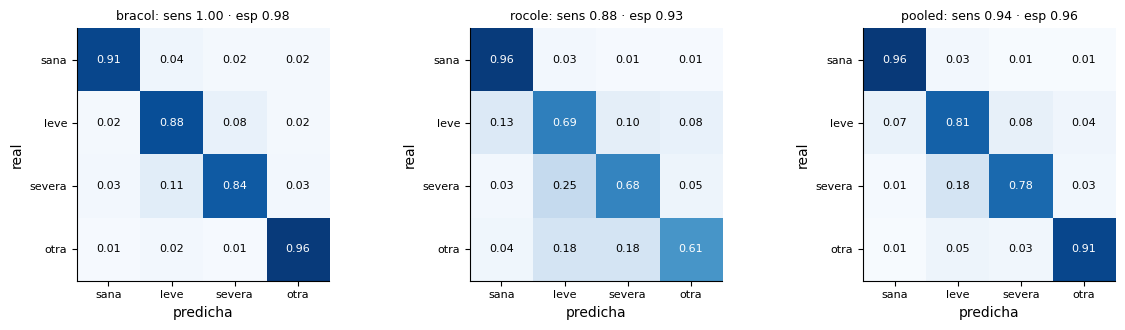

P(O | R) del modelo (filas: predicha; columnas: bajo, medio, alto):


,bajo,medio,alto
sana,0.756,0.720,0.663
leve,0.042,0.072,0.119
severa,0.018,0.032,0.054
otra,0.184,0.177,0.165


In [3]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
names = ["sana", "leve", "severa", "otra"]
for ax, src in zip(axes, ["bracol", "rocole", "pooled"]):
    counts = load_confusion_counts(src); pol = obs_given_leaf(counts, cfg["confusion"]["alpha"])
    ax.imshow(pol, vmin=0, vmax=1, cmap="Blues")
    for i in range(4):
        for j in range(4):
            ax.text(j, i, f"{pol[i, j]:.2f}", ha="center", va="center", fontsize=8, color="white" if pol[i, j] > 0.5 else "black")
    sens, spec = sensitivity_specificity(counts)
    ax.set_title(f"{src}: sens {sens:.2f} · esp {spec:.2f}", fontsize=9)
    ax.set_xticks(range(4)); ax.set_xticklabels(names, fontsize=8); ax.set_yticks(range(4)); ax.set_yticklabels(names, fontsize=8)
    ax.set_xlabel("predicha"); ax.set_ylabel("real")
plt.tight_layout(); plt.show()
print("P(O | R) del modelo (filas: predicha; columnas: bajo, medio, alto):")
display(pd.DataFrame(model.o_given_r, index=["sana", "leve", "severa", "otra"], columns=["bajo", "medio", "alto"]).round(3))

## 3. Cómo se mueve la creencia con las fotos
Con clima neutro, la creencia sobre el nivel de la parcela según cuántas de las `n` hojas muestran roya.

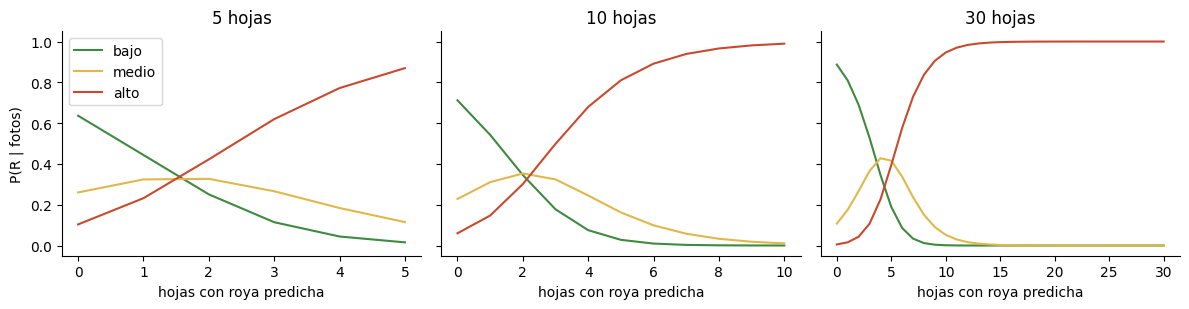

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2), sharey=True)
for ax, n in zip(axes, [5, 10, 30]):
    ks = list(range(n + 1)); post = np.array([model.belief(None, [1] * k + [0] * (n - k)).posterior for k in ks])
    for j, (name, color) in enumerate(zip(["bajo", "medio", "alto"], ["#3F8A3E", "#E0B84A", "#C84A2E"])):
        ax.plot(ks, post[:, j], label=name, color=color)
    ax.set_title(f"{n} hojas"); ax.set_xlabel("hojas con roya predicha")
axes[0].set_ylabel("P(R | fotos)"); axes[0].legend(); plt.tight_layout(); plt.show()

Con pocas hojas las curvas son suaves y con mucha incertidumbre: cinco hojas no bastan para separar un nivel del otro; con 30 la creencia ya se
concentra. Es el mismo argumento estadístico de `docs/decision_umbral_roya.md` (no se puede resolver un umbral de 5 % con 10 fotos).

## 4. Qué decide el QMDP
Acción recomendada según la creencia de roya alta (el resto se reparte en bajo y medio por igual), para una parcela de 1,400 m.

In [5]:
Q = solve_parcel(ParcelaProfile(1400, 1, 75)).Q
grid = np.linspace(0, 1, 11)
table = pd.DataFrame({MONTH_NAMES[m - 1]: [qmdp([(1 - p) / 2, (1 - p) / 2, p], m, Q).action_name for p in grid] for m in range(1, 13)},
                     index=[f"P(alto)={p:.1f}" for p in grid])
display(table)

,ene,feb,mar,abr,may,jun,jul,ago,sep,oct,nov,dic
P(alto)=0.0,triazol,nada,nada,nada,nada,nada,cobre,cobre,triazol,triazol,triazol,triazol
P(alto)=0.1,triazol,nada,nada,nada,nada,cobre,cobre,triazol,triazol,triazol,triazol,triazol
P(alto)=0.2,triazol,nada,nada,nada,nada,cobre,cobre,triazol,triazol,triazol,triazol,triazol
P(alto)=0.3,triazol,nada,nada,nada,cobre,cobre,cobre,triazol,triazol,triazol,triazol,triazol
P(alto)=0.4,triazol,nada,nada,nada,cobre,cobre,cobre,triazol,triazol,triazol,triazol,triazol
P(alto)=0.5,triazol,cobre,cobre,cobre,cobre,cobre,cobre,triazol,triazol,triazol,triazol,triazol
P(alto)=0.6,triazol,cobre,cobre,cobre,cobre,cobre,cobre,triazol,triazol,triazol,triazol,triazol
P(alto)=0.7,triazol,cobre,cobre,cobre,cobre,cobre,cobre,triazol,triazol,triazol,triazol,triazol
P(alto)=0.8,triazol,cobre,cobre,cobre,cobre,cobre,cobre,triazol,triazol,triazol,triazol,triazol
P(alto)=0.9,triazol,cobre,cobre,cobre,cobre,cobre,cobre,triazol,triazol,triazol,triazol,triazol


## 5. Valor de la información en el mundo simulado
Ingreso anual simulado (USD/ha) frente a no tener información (`B0`), media de 24 región-años con error estándar entre ellos. Detalle de
los escenarios y supuestos en `src/fusion/simulate.py`.

In [6]:
res = pd.read_csv(FUS / "voi_resumen.csv")
order = ["A_techo", "B0_sin_informacion", "B_clima_observado", "C_pronostico", "C0_pronostico_perfecto", "D0_solo_CNN", "D_pronostico_y_CNN"]
for stale, g in res.groupby("retraso"):
    print(f"Retraso de ERA5 en el pronóstico: {stale} días")
    display(g.set_index("escenario").loc[order, ["ingreso_medio", "vs_sin_informacion", "error_estandar", "aplicaciones", "meses_roya_alta", "fraccion_del_techo"]].round(2))

Retraso de ERA5 en el pronóstico: 0 días


,ingreso_medio,vs_sin_informacion,error_estandar,aplicaciones,meses_roya_alta,fraccion_del_techo
escenario,,,,,,
A_techo,4271.48,149.70,4.57,8.10,1.40,1.00
B0_sin_informacion,4121.78,0.00,0.00,8.67,1.33,0.00
B_clima_observado,4112.03,-9.76,3.17,8.79,1.43,-0.07
C_pronostico,4119.22,-2.56,1.24,8.62,1.41,-0.02
C0_pronostico_perfecto,4114.28,-7.51,2.80,8.67,1.41,-0.05
D0_solo_CNN,4131.10,9.32,2.20,8.77,1.38,0.06
D_pronostico_y_CNN,4123.88,2.10,1.97,8.71,1.40,0.01


Retraso de ERA5 en el pronóstico: 5 días


,ingreso_medio,vs_sin_informacion,error_estandar,aplicaciones,meses_roya_alta,fraccion_del_techo
escenario,,,,,,
A_techo,4271.48,149.70,4.57,8.10,1.40,1.00
B0_sin_informacion,4121.78,0.00,0.00,8.67,1.33,0.00
B_clima_observado,4112.03,-9.76,3.17,8.79,1.43,-0.07
C_pronostico,4120.56,-1.22,0.68,8.62,1.39,-0.01
C0_pronostico_perfecto,4114.28,-7.51,2.80,8.67,1.41,-0.05
D0_solo_CNN,4131.10,9.32,2.20,8.77,1.38,0.06
D_pronostico_y_CNN,4125.33,3.55,1.87,8.72,1.42,0.02


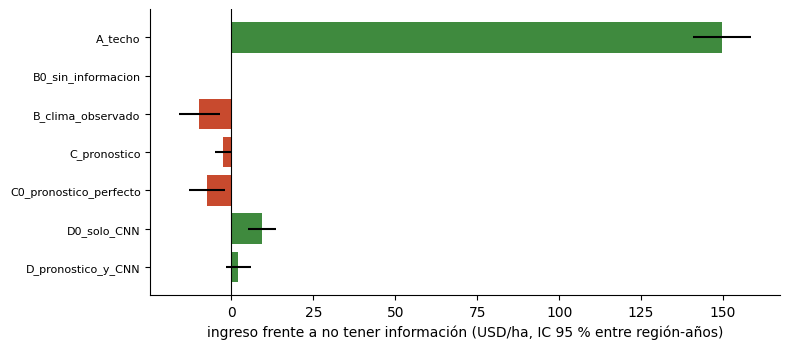

In [7]:
g = res[res["retraso"] == res["retraso"].min()].set_index("escenario").loc[order]
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh(range(len(g)), g["vs_sin_informacion"], xerr=1.96 * g["error_estandar"], color=["#3F8A3E" if v > 0 else "#C84A2E" for v in g["vs_sin_informacion"]])
ax.set_yticks(range(len(g))); ax.set_yticklabels(g.index, fontsize=8); ax.invert_yaxis(); ax.axvline(0, color="k", lw=0.8)
ax.set_xlabel("ingreso frente a no tener información (USD/ha, IC 95 % entre región-años)"); plt.tight_layout(); plt.show()

**Lectura.** (1) Conocer el nivel de roya vale poco en dinero en este MDP heredado (el techo es una fracción pequeña del ingreso). (2) **Las fotos son lo único que
aporta**; (3) **el clima no ayuda y hasta resta**, incluso con un pronóstico perfecto: no es un problema del pronosticador. La sección 7 muestra por qué.

## 6. Sensibilidad del valor de la información
Número de hojas, calidad real de la CNN en el mundo simulado y fuerza del clima.

In [8]:
sens = pd.read_csv(FUS / "voi_sensibilidad.csv")
key = sens[sens["escenario"].isin(["A_techo", "D0_solo_CNN", "D_pronostico_y_CNN", "C0_pronostico_perfecto"])]
display(key.pivot_table(index=["gamma", "hojas", "confusion_mundo"], columns="escenario", values="vs_sin_informacion").round(1))

escenario                    A_techo  C0_pronostico_perfecto  D0_solo_CNN  D_pronostico_y_CNN
gamma hojas confusion_mundo                                                                  
0.00  5     pooled             163.6                    -8.3          3.8                 0.7
            rocole             163.6                    -8.3         -0.4                -1.6
      10    pooled             163.6                    -8.3         10.7                 5.7
            rocole             163.6                    -8.3          0.1                -2.4
      30    pooled             163.6                    -8.3         49.6                39.1
            rocole             163.6                    -8.3          6.5                 2.7
0.15  5     pooled             150.1                    -7.5          2.3                -1.5
            rocole             150.1                    -7.5          0.1                -1.3
      10    pooled             150.1                    -7.5          7.9                 2.9
            rocole             150.1                    -7.5         -0.9                -2.6
      30    pooled             150.1                    -7.5         44.5                35.8
            rocole             150.1                    -7.5          8.1                 5.2
0.30  5     pooled             131.0                    -8.3          0.7                -4.0
            rocole             131.0                    -8.3          0.2                -2.7
      10    pooled             131.0                    -8.3          8.9                 4.3
            rocole             131.0                    -8.3         -0.7                -2.9
      30    pooled             131.0                    -8.3         40.5                35.3
            rocole             131.0                    -8.3          7.1                 8.1

Cuando la CNN real se parece menos a la matriz con que se construyó la red (`confusion_mundo = rocole`), las fotos aportan mucho menos: **una red demasiado
confiada en su clasificador pierde valor**. Con 30 hojas y una CNN como la medida en BRACOL+RoCoLe, las fotos recuperan una fracción grande del techo.

## 7. ¿Por qué el clima no ayuda en este mundo?
Correlación entre el clima de las dos semanas (z) y el nivel de roya del mes, por fuerza del clima en el mundo simulado, y el valor del clima cuando la
pendiente que cree la red varía.

In [9]:
diag = pd.read_csv(FUS / "diagnostico_clima.csv"); display(diag.round(3))

,gamma,"corr(z, nivel)",nivel medio z<=-2,nivel medio z>=2,P(alto) z<=-2,P(alto) z>=2
0,0.00,-0.038,0.453,0.372,0.102,0.084
1,0.15,0.029,0.405,0.453,0.088,0.115
2,0.30,0.103,0.355,0.548,0.070,0.150
3,0.60,0.249,0.288,0.781,0.054,0.250


In [10]:
path = FUS / "voi_pendiente_vs_mundo.csv"
if path.exists():
    grid = pd.read_csv(path)
    clima = grid[grid["escenario"].isin(["C0_pronostico_perfecto", "C_pronostico"])]
    display(clima.pivot_table(index=["pendiente_modelo", "gamma"], columns="escenario", values="vs_sin_informacion").round(1))
else:
    print("Falta experiments/fusion/voi_pendiente_vs_mundo.csv (python -m src.fusion.simulate --slopes ... --gammas ...)")

escenario               C0_pronostico_perfecto  C_pronostico
pendiente_modelo gamma                                      
0.10             0.00                     -2.9          -2.7
                 0.15                     -2.4          -4.3
                 0.30                     -3.2          -5.1
                 0.60                     -3.5          -4.1
0.25             0.00                     -5.9          -0.7
                 0.15                     -7.8          -4.2
                 0.30                     -9.8          -8.7
                 0.60                    -12.6          -9.7
0.50             0.00                     -6.9          -0.0
                 0.15                    -10.4          -4.9
                 0.30                    -11.3         -12.0
                 0.60                    -14.6         -10.6

El nivel de roya del mes depende sobre todo del mes anterior (persistencia del MDP). Mientras el clima de las dos semanas no mueva el nivel más que eso,
ninguna evidencia climática puede ayudar a elegir la acción; y una red que **cree** un vínculo más fuerte que el real convierte esa evidencia en ruido que
empeora la decisión. Con datos reales de incidencia (ANACAFE/CEDICAFE) se podría medir ese vínculo y calibrar la pendiente.

## 8. Sensibilidad de la decisión a los supuestos de diseño
Se mueve cada supuesto y se mide en cuántos de 81 casos cambia la acción recomendada.

In [11]:
display(pd.read_csv(FUS / "sensibilidad_resumen.csv").round(3).set_index("variacion"))

,casos,accion_cambia,cambio_medio_p_alto,cambio_max_p_alto
variacion,,,,
base,81,0.000,0.000,0.000
cortes 3 % / 8 % (incidencia 1 / 5 / 12 %),81,0.000,0.017,0.092
cortes 7 % / 15 % (incidencia 3 / 10 / 20 %),81,0.025,0.021,0.114
proporción severa 0.1,81,0.000,0.011,0.044
proporción severa 0.5,81,0.012,0.014,0.054
otra afección 0.05,81,0.000,0.005,0.024
otra afección 0.4,81,0.012,0.006,0.026
clima neutro: P(R≥medio) 0.25,81,0.074,0.040,0.139
clima neutro: P(R≥medio) 0.65,81,0.062,0.073,0.208


Casi ningún supuesto cambia la acción en más de una pequeña fracción de casos; el que más pesa es **cuánto cuenta cada hoja** (independencia entre hojas) y,
después, el nivel de riesgo con clima neutro.

## 9. Conclusiones
- La arquitectura funciona de punta a punta (pronóstico y fotos → creencia → acción) y la red extendida coincide con `pgmpy`.
- En el mundo simulado **el aporte del Deep Learning a la decisión viene de las fotos, no del pronóstico**, y depende de cuántas hojas se fotografíen y de que la red no
  sobreestime a la CNN.
- El pronóstico sigue siendo útil como información para el productor (lluvia y humedad próximas), pero no está demostrado que mejore la acción recomendada; para
  demostrarlo hacen falta datos reales de incidencia.
- Todo lo anterior depende de supuestos declarados; ninguna cifra de este notebook es una medición de campo.